![Banner](../images/09_09_banner_rs_image_classification.png)


# Multi-sensor image fusion

No single sensor is fine enough, frequent enough, cloud-free and sensitive to everything at once.


## Overview

MODIS images the Earth every day but with 500 m pixels; Landsat and Sentinel-2 resolve fields at 10 m to 30 m but revisit every five to sixteen days and lose dates to clouds; Sentinel-1 radar sees through clouds but measures structure and moisture rather than colour; commercial and aerial images (Planet, RapidEye, NAIP) show individual trees and buildings but cover little area and few dates. **Fusion** combines them so that one sensor's strength covers another's gap.

This notebook works on one small rural area west of Rochester, New York (about 30 km², the `Image_Fusion` AOI) in July 2019, where seven sensors observed the same fields within a few weeks:

| Sensor | Date(s) in 2019 | Pixel | Bands used | Source |
|---|---|---|---|---|
| MODIS Terra MOD09A1, 8-day composites | 18 Jun to 12 Aug (7 composites) | 463 m | red, NIR, blue, green, SWIR 1, SWIR 2 | downloaded (Planetary Computer) |
| Sentinel-1A RTC, ascending orbit 4 | 29 Jun, 11 Jul, 23 Jul, 4 Aug | 10 m | VV, VH backscatter | downloaded (Planetary Computer) |
| Sentinel-2A L2A | 8 Jul | 10 m | blue, green, red, NIR, SWIR 1, SWIR 2 | local |
| Landsat 8 OLI L2 | 9 Jul | 30 m | coastal to SWIR 2 | local |
| PlanetScope | 8 Jul, 14 Jul | 3 m | blue, green, red, NIR | local |
| RapidEye | 24 Jul | 5 m | blue, green, red, red edge, NIR | local |
| NAIP aerial image | 14 Jul | 0.6 m | red, green, blue, NIR | local |
| USDA Cropland Data Layer (CDL) 2019 | 2019 season | 30 m | crop type and confidence | downloaded (Planetary Computer) |

Every fusion result is scored against a real observation that the method did not use.


## Core concepts

### Learning objectives

1. Read the local images, download MODIS, Sentinel-1 and the CDL for the area of interest, and line up the dates.
2. Predict Landsat-like 30 m images with STARFM and score them against PlanetScope and RapidEye.
3. Fill a synthetic cloud in Sentinel-2 from Sentinel-1 and MODIS.
4. Compare vegetation cover measured at 0.6 m with what Sentinel-2, Landsat and MODIS pixels see.
5. Map CDL classes from optical, radar and MODIS features alone and with early and late fusion, on a spatial-block split.
6. Write the fused products as Cloud-Optimized GeoTIFFs.

### Contents

1. Workflow and GeoLattice functions
2. Spatiotemporal fusion with STARFM
3. Optical-SAR gap filling
4. Scale effects: from NAIP to Sentinel-2, Landsat and MODIS pixels
5. Multi-sensor classification
6. Export the fused products
7. Interpretation and limitations


## Workflow and GeoLattice functions

1. Read the local images, download the MODIS 8-day composites, the Sentinel-1 scenes and the CDL for the AOI once with `get_images` (later runs read them from the local drive), and line up the acquisition dates.
2. Spatiotemporal fusion: predict Landsat-like 30 m images for 14 and 24 July from the 9 July Landsat image and the MODIS composites with `geolattice.rsense.fusion.starfm`, and score them against PlanetScope (14 July) and RapidEye (24 July).
3. Optical-SAR gap filling: cover part of the Sentinel-2 image with a synthetic cloud and fill it from Sentinel-1 (and MODIS) with `sar_assisted_gap_fill`.
4. Scale effects: compute vegetation cover from the 0.6 m NAIP image, aggregate it with `geolattice.rsense.fusion.upscale`, and compare it with what Sentinel-2, Landsat and MODIS pixels see, using `geolattice.rsense.fusion.compare`.
5. Multi-sensor classification: map the CDL classes from optical, radar and MODIS time-series features alone, and with early (`fuse_early`) and late (`fuse_late`) fusion, on a spatial-block split.
6. Write the fused products as Cloud-Optimized GeoTIFFs.


### Imports, paths, and settings

The cell imports the libraries, finds the repository and the `Image_Fusion` folder, and defines `ensure_download`: it reads a product from the local drive when an earlier run has saved it, and otherwise searches Planetary Computer and downloads it with `get_images`, clipped to the AOI. MODIS 500 m composites come from the `modis-09A1-061` collection (Terra only, `MOD09A1`), Sentinel-1 from the radiometrically terrain-corrected `sentinel-1-rtc` collection, and the CDL from `usda-cdl`.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import os  # environment variables
import sys  # Python import path
import time  # timing
import warnings  # warning control
from pathlib import Path  # file paths

import geopandas as gpd  # the AOI polygon
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster reading
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters
from matplotlib.colors import ListedColormap  # class colours
from rasterio.enums import Resampling  # resampling methods
from scipy import ndimage  # nearest-valid filling
from skimage.filters import threshold_otsu  # automatic vegetation threshold
from sklearn.ensemble import RandomForestClassifier  # the classifier

warnings.filterwarnings("ignore")  # hide library warnings

# Prefer this checkout's code when launched from the repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

import geolattice.rsense as rs  # GeoLattice remote sensing (fusion, reading, writing)
import geolattice.rsense.classify.image_classification as ic  # fusion helpers, splits and accuracy
from geolattice.rsense.get_images import get_images, search_images  # search and download

if ROOT is None:  # not started inside the repository
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")  # stop
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_09_image_classification"
IF = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_09_image_classification" / "Image_Fusion"  # the fusion data folder
OUTPUT_DIR = NOTEBOOK_DIR / "outputs" / "image_fusion"  # products of this notebook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed
aoi = gpd.read_file(IF / "AOI" / "rural_aoi_GCS.shp")  # the study area (WGS 84)
SEED = 7  # random seed
rng = np.random.default_rng(SEED)  # random generator


def ensure_download(folder, collection, dates, bands, id_prefix=None):  # local first, else download once
    out = IF / folder  # where the scenes are kept
    if any(out.glob("*/item.json")):  # downloaded before
        # report the local scenes
        print(f"{folder}: reading {len(list(out.glob('*/item.json')))} scenes from the local drive")
        return out  # nothing to download
    # search the Planetary Computer
    found = search_images(aoi=aoi, dates=dates, source="planetary", collection=collection, limit=50, quiet=True)
    ids = sorted(i.id for i in found.items if id_prefix is None or i.id.startswith(id_prefix))  # scenes to keep
    get_images(out, search=found, ids=ids, bands=bands, mode="clip", quiet=True)  # download, clipped to the AOI
    print(f"{folder}: downloaded {len(ids)} scenes")  # report
    return out  # the folder


# MODIS band names
MODIS_BANDS = {"sur_refl_b01": "red", "sur_refl_b02": "nir", "sur_refl_b03": "blue", "sur_refl_b04": "green",
               "sur_refl_b06": "swir1", "sur_refl_b07": "swir2"}  # MODIS asset -> band name
# MODIS 8-day reflectance for the summer of 2019
MODIS_DIR = ensure_download("MODIS_MOD09A1_2019", "modis-09A1-061", ("2019-06-15", "2019-08-12"),
                            [*MODIS_BANDS, "sur_refl_state_500m"], id_prefix="MOD09A1")  # Terra 8-day, 500 m
S1_DIR = ensure_download("Sentinel_1_RTC_2019", "sentinel-1-rtc", ("2019-06-20", "2019-08-10"), ["vv", "vh"])  # Sentinel-1 RTC, VV and VH
# CDL 2019 for the AOI
CDL_DIR = ensure_download("CDL_2019", "usda-cdl", ("2019-01-01", "2019-12-31"), ["cropland", "confidence"],
                          id_prefix="cropland_2019")  # crop map and its confidence
print("AOI area:", round(float(aoi.to_crs(32617).area.sum()) / 1e6, 1), "km2")  # size of the study area


MODIS_MOD09A1_2019: reading 7 scenes from the local drive
Sentinel_1_RTC_2019: reading 4 scenes from the local drive
CDL_2019: reading 1 scenes from the local drive
AOI area: 30.0 km2


### Read every sensor as reflectance

Each product is read as an `(band, y, x)` array with named bands, scaled to surface reflectance (0 to 1), with no-data and flagged pixels set to missing:

- **Landsat 8** and **Sentinel-2** are already scaled; their clear-sky masks remove the few cloudy pixels.
- **PlanetScope** and **RapidEye** analytic surface reflectance are stored as reflectance × 10,000.
- **NAIP** is an 8-bit-like digital-number image without radiometric calibration; it is used only for its spatial detail (vegetation versus non-vegetation), never as reflectance.
- **MODIS** MOD09A1 reflectance is scaled by 0.0001; the `state` quality band removes cloudy, cloud-shadowed and cirrus pixels. Each composite takes, for every pixel, the best observation of an 8-day window starting on its day of year.
- **Sentinel-1** RTC backscatter (gamma-nought) is converted to decibels.

Two local files need a warning: `RapidEye_Rural_AOI_July_14_2019.tif` is pixel-for-pixel identical to the 24 July file (the only RapidEye metadata in the folder is for 24 July), so RapidEye is used as one date, 24 July.


In [2]:
def read_img(path, names, scale=1.0, mask=None):  # (band, y, x) reflectance with named bands
    da = rioxarray.open_rasterio(path, masked=True).astype("float32") * scale  # read and scale
    da = da.where(da > 0).assign_coords(band=names)  # zero is no data in these products
    if mask is not None:  # a clear-sky mask (1 = clear)
        m = rioxarray.open_rasterio(mask).squeeze(drop=True)  # the mask
        da = da.where(m == 1)  # keep clear pixels only
    return da  # the image


LS_DIR, S2_DIR = IF / "Landsat8_20190709", IF / "Sentinel_2" / "L2A_T17TQH_20190708"  # local folders
landsat = read_img(LS_DIR / "landsat8_20190709_surface_reflectance_30m.tif",  # Landsat 8, 9 July, 30 m
                   ["coastal", "blue", "green", "red", "nir", "swir1", "swir2"], mask=LS_DIR / "clear_mask.tif")
s2 = read_img(S2_DIR / "sentinel2_20190708_surface_reflectance_6band_10m.tif",  # Sentinel-2, 8 July, 10 m
              ["blue", "green", "red", "nir", "swir1", "swir2"], mask=S2_DIR / "clear_mask_10m.tif")
planet = {"2019-07-08": read_img(IF / "Planet/July_08_2019/Planet_Rural_AOI_July_08_2019.tif", ["blue", "green", "red", "nir"], 1e-4),  # PlanetScope, 3 m, two dates
          "2019-07-14": read_img(IF / "Planet/July_14_2019/Planet_Rural_AOI_July_14_2019_NAD.tif", ["blue", "green", "red", "nir"], 1e-4)}
rapideye = read_img(IF / "RapidEye/RapidEye_Rural_AOI_July_24_2019.tif", ["blue", "green", "red", "rededge", "nir"], 1e-4)  # RapidEye, 24 July, 5 m


def modis(doy):  # one MOD09A1 composite (start day of year) with its cloud mask applied
    folder = next(MODIS_DIR.glob(f"MOD09A1.A2019{doy:03d}.*"))  # its scene folder
    # the seven MODIS bands
    bands = [rioxarray.open_rasterio(folder / f"{a}.tif", masked=True).squeeze(drop=True) for a in MODIS_BANDS]
    da = xr.concat(bands, dim="band").assign_coords(band=list(MODIS_BANDS.values())) * 1e-4  # reflectance
    # MODIS quality (state) flags
    state = rioxarray.open_rasterio(folder / "sur_refl_state_500m.tif").squeeze(drop=True).values.astype(int)
    clear = ((state & 0b11) == 0) & ((state >> 2 & 1) == 0) & ((state >> 8 & 0b11) == 0)  # no cloud, shadow, cirrus
    return da.where(clear).astype("float32").rio.write_crs(bands[0].rio.crs)  # masked composite


MODIS_DOY = sorted(int(p.name.split(".")[1][5:]) for p in MODIS_DIR.glob("MOD09A1.*"))  # composite start days
mod = {d: modis(d) for d in MODIS_DOY}  # every composite
mod_start = {d: pd.Timestamp("2019-01-01") + pd.Timedelta(days=d - 1) for d in MODIS_DOY}  # first day of each


def s1_db(folder):  # VV and VH backscatter in dB
    # VV and VH as one array
    da = xr.concat([rioxarray.open_rasterio(folder / f"{p}.tif", masked=True).squeeze(drop=True) for p in ("vv", "vh")],
                   dim="band").assign_coords(band=["vv", "vh"])  # linear gamma-nought
    crs = rioxarray.open_rasterio(folder / "vv.tif").rio.crs  # its CRS
    return (10 * np.log10(da.where(da > 0))).astype("float32").rio.write_crs(crs)  # decibels


s1 = {pd.Timestamp(p.name.split("_")[4][:8]): s1_db(p) for p in sorted(S1_DIR.glob("S1A_*"))}  # date -> (band, y, x)
cdl_dir = next(CDL_DIR.glob("cropland_2019*"))  # the CDL scene folder
cdl = rioxarray.open_rasterio(cdl_dir / "cropland.tif").squeeze(drop=True)  # crop codes (EPSG:5070)
cdl_conf = rioxarray.open_rasterio(cdl_dir / "confidence.tif").squeeze(drop=True)  # per-pixel confidence (%)

summary = pd.DataFrame({  # one row per product
    "Landsat 8, 9 Jul": landsat.rio.resolution()[0], "Sentinel-2, 8 Jul": s2.rio.resolution()[0],
    "PlanetScope, 8 Jul": planet["2019-07-08"].rio.resolution()[0], "PlanetScope, 14 Jul": planet["2019-07-14"].rio.resolution()[0],
    "RapidEye, 24 Jul": rapideye.rio.resolution()[0], "MODIS MOD09A1 (x7)": mod[MODIS_DOY[0]].rio.resolution()[0],
    "Sentinel-1 RTC (x4)": next(iter(s1.values())).rio.resolution()[0], "CDL 2019": cdl.rio.resolution()[0]}, index=["pixel (m)"]).T
summary["share of the grid with data"] = [float(landsat.sel(band="red").notnull().mean()), float(s2.sel(band="red").notnull().mean()),  # share of each grid with data
                                     np.nan, np.nan, np.nan, float(np.mean([mod[d].sel(band="red").notnull().mean() for d in MODIS_DOY])),
                                     np.nan, np.nan]  # share of pixels with data
summary.round(3)  # show it

,pixel (m),share of the grid with data
"Landsat 8, 9 Jul",30.000,0.865
"Sentinel-2, 8 Jul",10.000,0.868
"PlanetScope, 8 Jul",3.000,NaN
"PlanetScope, 14 Jul",3.000,NaN
"RapidEye, 24 Jul",5.000,NaN
MODIS MOD09A1 (x7),463.313,0.960
Sentinel-1 RTC (x4),10.000,NaN
CDL 2019,30.000,NaN


### Line up the dates

Fusion assumes that what one sensor saw is still there when the other looks. The figure places every acquisition on one time axis: the 8-day MODIS windows as bars, the other sensors as points. Sentinel-2 and Landsat (8 and 9 July) form a near-simultaneous pair with the first PlanetScope image; the second PlanetScope image and NAIP (14 July) and RapidEye (24 July) come later in the month, each inside a MODIS window, which is exactly what spatiotemporal fusion needs.


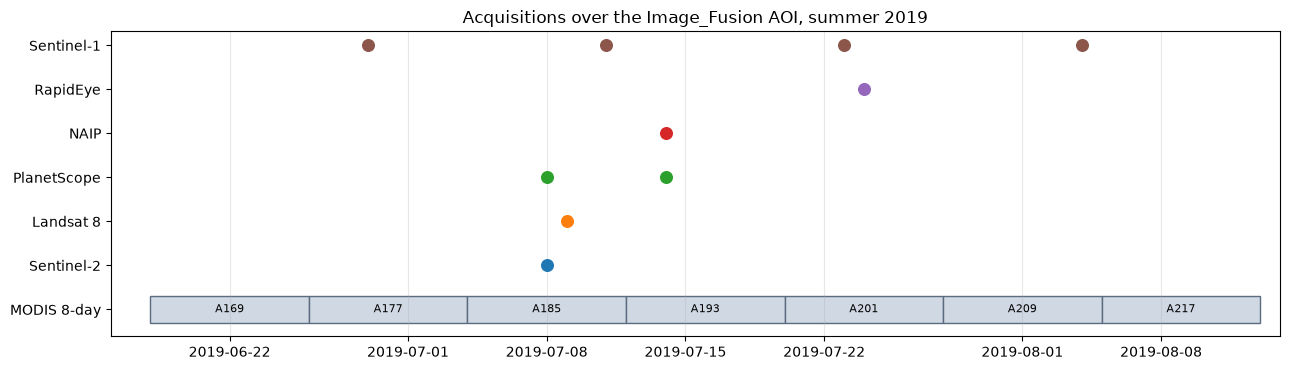

In [3]:
# acquisition dates per sensor
events = {"Sentinel-2": ["2019-07-08"], "Landsat 8": ["2019-07-09"], "PlanetScope": ["2019-07-08", "2019-07-14"],
          "NAIP": ["2019-07-14"], "RapidEye": ["2019-07-24"], "Sentinel-1": [str(d.date()) for d in s1]}  # dates per sensor
fig, ax = plt.subplots(figsize=(13, 3.8))  # one panel
for d in MODIS_DOY:  # MODIS 8-day windows as bars
    ax.barh(0, 8, left=mod_start[d], height=0.6, color="#cfd8e3", edgecolor="#5b6b80")  # the window
    ax.text(mod_start[d] + pd.Timedelta(days=4), 0, f"A{d}", ha="center", va="center", fontsize=8)  # its name
for i, (name, dates) in enumerate(events.items(), start=1):  # every other sensor
    ax.scatter(pd.to_datetime(dates), [i] * len(dates), s=70, zorder=3)  # its acquisitions
ax.set_yticks(range(len(events) + 1)); ax.set_yticklabels(["MODIS 8-day"] + list(events))  # sensor names
ax.set_xlim(pd.Timestamp("2019-06-16"), pd.Timestamp("2019-08-14")); ax.grid(axis="x", alpha=0.3)  # date range
ax.set_title("Acquisitions over the Image_Fusion AOI, summer 2019"); plt.tight_layout(); plt.show()  # draw

## Spatiotemporal fusion with STARFM

### Predict Landsat-like images for 14 and 24 July

STARFM (Gao et al. 2006) predicts a fine image at a date when only the coarse sensor observed. From a fine/coarse pair at t1 (Landsat on 9 July with the MODIS composite of 4 to 11 July) and a coarse image at t2, each fine pixel takes its t1 value plus the coarse-scale change, averaged over spectrally similar neighbours inside a moving window and weighted towards neighbours whose coarse pixel changed little and matched the fine image well. `geolattice.rsense.fusion.starfm` expects the coarse images already resampled to the fine grid; here MODIS is reprojected onto the 30 m Landsat grid by nearest neighbour, so every 463 m MODIS pixel becomes a block of about 15 × 15 Landsat pixels.

Missing pixels need care: in the current `starfm`, a missing value anywhere inside a pixel's 31-pixel window makes that pixel's prediction missing too, and the 20 to 27 July composite has clouds over part of the AOI. `starfm_masked` therefore fills missing inputs with the nearest valid value before calling `starfm`, and masks the prediction again wherever an input was really missing.

Two prediction dates are tested, each against a real fine image the method never saw:

- **14 July** with the MODIS composite of 12 to 19 July; truth: PlanetScope of 14 July;
- **24 July** with the MODIS composite of 20 to 27 July; truth: RapidEye of 24 July.


In [4]:
LS_GRID = landsat.sel(band="red")  # the 30 m target grid
on_ls = lambda da, how: da.rio.reproject_match(LS_GRID, resampling=how)  # put any raster on the Landsat grid
T1_DOY = 185  # MODIS composite of 4-11 July, paired with Landsat of 9 July
# target dates: day of year, name and image
TARGETS = {"2019-07-14": (193, "PlanetScope 14 Jul", planet["2019-07-14"]),
           "2019-07-24": (201, "RapidEye 24 Jul", rapideye)}  # date -> (MODIS composite, truth name, truth image)
coarse = {d: on_ls(mod[d], Resampling.nearest) for d in (T1_DOY, 193, 201)}  # MODIS blocks on the 30 m grid


def fill_nearest(a):  # replace missing pixels with the nearest valid value (window input only)
    miss = np.isnan(a)  # missing pixels
    if not miss.any():  # nothing to fill
        return a  # unchanged
    idx = ndimage.distance_transform_edt(miss, return_distances=False, return_indices=True)  # nearest valid pixel
    return a[tuple(idx)]  # filled copy


def starfm_masked(f1, c1, c2, **kw):  # STARFM on filled inputs, masked where any input was missing
    valid = np.isfinite(f1.values) & np.isfinite(c1.values) & np.isfinite(c2.values)  # real observations
    p = rs.fusion.starfm(*(a.copy(data=fill_nearest(a.values)) for a in (f1, c1, c2)), **kw)  # the fusion
    return p.where(valid)  # no prediction where an input was missing
print({f"A{d}": f"{mod_start[d]:%d %b}-{mod_start[d] + pd.Timedelta(days=7):%d %b}" for d in coarse})  # the three composites and their windows

{'A185': '04 Jul-11 Jul', 'A193': '12 Jul-19 Jul', 'A201': '20 Jul-27 Jul'}


### A cross-sensor reference

PlanetScope and RapidEye have other spectral bands and calibrations than Landsat, so their reflectances cannot be compared directly. Each is first averaged onto the 30 m Landsat grid with `upscale`, and then put on Landsat's radiometric scale with a **pseudo-invariant feature** (PIF) normalisation: a straight line per band, fitted between the reference sensor and Landsat on pixels that are not expected to change within two weeks (CDL forest and developed land). Crop fields are left out of the fit, because their change is exactly what STARFM has to predict.


In [5]:
cdl30 = on_ls(cdl, Resampling.nearest).values  # CDL codes on the Landsat grid
PIF = np.isin(cdl30, [121, 122, 123, 124, 141, 142, 143])  # developed and forest: stable over two weeks
truth, pif_fit = {}, {}  # Landsat-scaled reference images and their fits
for date, (_, name, fine) in TARGETS.items():  # each reference image
    # fine image averaged onto the Landsat grid
    agg = xr.concat([rs.fusion.upscale(fine.sel(band=b), LS_GRID, method="mean") for b in ("red", "nir")],
                    dim="band").assign_coords(band=["red", "nir"])  # averaged onto the 30 m grid
    out = []  # normalised bands
    for b in ("red", "nir"):  # each band
        x, y = agg.sel(band=b).values, landsat.sel(band=b).values  # reference and Landsat
        ok = PIF & np.isfinite(x) & np.isfinite(y)  # usable invariant pixels
        slope, icpt = np.polyfit(x[ok], y[ok], 1)  # Landsat = slope * reference + intercept
        # the fit of each sensor and band
        pif_fit[name, b] = {"slope": slope, "intercept": icpt, "PIF pixels": int(ok.sum()),
                            "r": float(np.corrcoef(x[ok], y[ok])[0, 1])}  # the fit
        out.append(agg.sel(band=b) * slope + icpt)  # rescaled band
    truth[date] = xr.concat(out, dim="band")  # the 30 m reference on Landsat's scale
pd.DataFrame(pif_fit).T.round(3)  # show the fits

slope  intercept  PIF pixels      r
PlanetScope 14 Jul red  0.825      0.017      6971.0  0.895
                   nir  0.750      0.107      6971.0  0.861
RapidEye 24 Jul    red  0.692      0.027      6967.0  0.816
                   nir  0.621      0.118      6967.0  0.860

The fits are far from one-to-one (slopes 0.62 to 0.83, intercepts up to 0.12) and the correlations on the stable pixels are 0.82 to 0.90: the two sensors measure the same surfaces on clearly different scales. That spread enters every score below as part of the reference.


### Run STARFM and score it

Four predictions of each date are compared with the reference, band by band:

- **no change**: the 9 July Landsat image itself;
- **MODIS at t2**: the coarse composite of the target date, resampled to 30 m (all change, no spatial detail);
- **Landsat + MODIS change**: the 9 July image plus the MODIS difference between the two composites, without STARFM's neighbour weighting;
- **STARFM**, with a 31-pixel (930 m) window.

All four are scored on the same pixels (where every prediction and the reference exist). The RMSE is reported over all of them and over the 10 % of pixels whose reference changed most since 9 July, where a good fusion method has to beat "no change".


In [6]:
t0 = time.time()  # start the timer
pred, rows = {}, []  # STARFM predictions and scores
for date, (doy, name, _) in TARGETS.items():  # each target date
    for b in ("red", "nir"):  # each band
        f1, c1, c2 = landsat.sel(band=b), coarse[T1_DOY].sel(band=b), coarse[doy].sel(band=b)  # STARFM inputs
        p = starfm_masked(f1, c1, c2, window=31, n_classes=4)  # the fusion
        pred[date, b] = p  # keep it
        ref = truth[date].sel(band=b).values  # the reference
        # candidate predictions for t2
        cands = {"no change (Landsat 9 Jul)": f1.values, "MODIS at t2": c2.values,
                 "Landsat + MODIS change": (f1 + c2 - c1).values, "STARFM": p.values}  # the four predictions
        common = np.isfinite(ref) & np.all([np.isfinite(v) for v in cands.values()], axis=0)  # same pixels for all
        ref = np.where(common, ref, np.nan)  # score on the common pixels only
        change = np.abs(ref - f1.values)  # how much the pixel changed
        big = change >= np.nanpercentile(change, 90)  # the 10 % most changed pixels
        for method, v in cands.items():  # score each
            e = v - ref  # error
            rows.append({"date": date, "band": b, "method": method, "pixels": int(common.sum()),  # one score row
                         "RMSE all": float(np.sqrt(np.nanmean(e ** 2))),
                         "RMSE most changed 10 %": float(np.sqrt(np.nanmean(e[big] ** 2)))})
print(f"STARFM for 2 dates x 2 bands in {time.time() - t0:.0f} s")  # run time
METHODS = ["no change (Landsat 9 Jul)", "MODIS at t2", "Landsat + MODIS change", "STARFM"]  # column order
starfm_tab = pd.DataFrame(rows).pivot_table(index=["date", "band"], columns="method", values=["RMSE all", "RMSE most changed 10 %"])  # scores as a table
starfm_tab = starfm_tab.reindex(columns=pd.MultiIndex.from_product([["RMSE all", "RMSE most changed 10 %"], METHODS]))  # columns in a fixed order
# pixels scored per date and band
print("pixels scored per date and band:", pd.DataFrame(rows).groupby(["date", "band"]).pixels.first().to_dict())
starfm_tab.round(4)  # show it

STARFM for 2 dates x 2 bands in 1 s
pixels scored per date and band: {('2019-07-14', 'nir'): 32847, ('2019-07-14', 'red'): 32847, ('2019-07-24', 'nir'): 26331, ('2019-07-24', 'red'): 26331}


RMSE all                                     \
                no change (Landsat 9 Jul) MODIS at t2 Landsat + MODIS change   
date       band                                                                
2019-07-14 nir                     0.0417      0.0539                 0.0464   
           red                     0.0215      0.0266                 0.0186   
2019-07-24 nir                     0.0593      0.0998                 0.1148   
           red                     0.0267      0.0274                 0.0271   

                           RMSE most changed 10 %              \
                 STARFM no change (Landsat 9 Jul) MODIS at t2   
date       band                                                 
2019-07-14 nir   0.0380                    0.0985      0.0547   
           red   0.0150                    0.0494      0.0358   
2019-07-24 nir   0.0943                    0.1358      0.0951   
           red   0.0216                    0.0624      0.0450   

                                                
                Landsat + MODIS change  STARFM  
date       band                                 
2019-07-14 nir                  0.0807  0.0787  
           red                  0.0319  0.0307  
2019-07-24 nir                  0.1361  0.1167  
           red                  0.0580  0.0502

**Reading the STARFM results.** On 14 July, five days after the Landsat image, STARFM has the lowest error of the four methods in both bands, and on the most-changed pixels it clearly beats "no change"; in the NIR the plain MODIS composite does even better on those pixels, because the largest changes (winter wheat harvest, hay cuts) are wide enough for MODIS to see. On 24 July, STARFM again wins in the red band, but in the NIR it is worse than simply keeping the 9 July image over all pixels, though better on the most-changed tenth. The MODIS NIR change between the two composites is larger than the change RapidEye shows: 8-day composites mix days and view angles, NIR reflectance depends strongly on the view angle, and the RapidEye reference needed its weakest calibration fit in the NIR. Fusion inherits every error of its coarse input.


The figure shows NDVI for 24 July: the 9 July Landsat image (input), the MODIS composite of 20 to 27 July (input), the STARFM prediction, and the RapidEye reference. STARFM keeps the field pattern of the Landsat image and changes each field by the amount MODIS saw nearby.


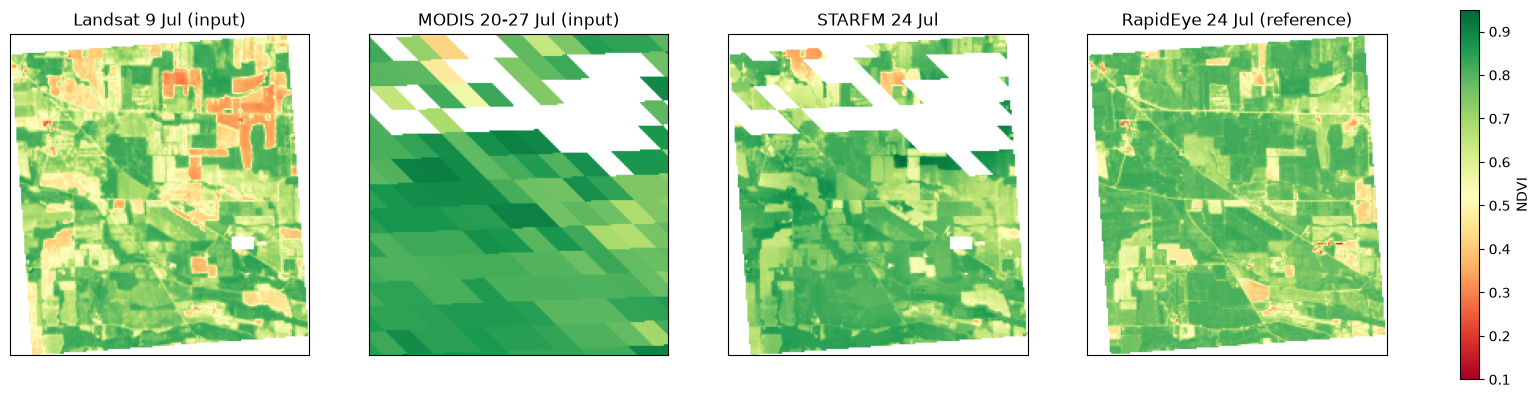

In [7]:
ndvi = lambda red, nir: (nir - red) / (nir + red)  # normalised difference vegetation index
panels = {"Landsat 9 Jul (input)": ndvi(landsat.sel(band="red"), landsat.sel(band="nir")),  # the four NDVI panels
          "MODIS 20-27 Jul (input)": ndvi(coarse[201].sel(band="red"), coarse[201].sel(band="nir")),
          "STARFM 24 Jul": ndvi(pred["2019-07-24", "red"], pred["2019-07-24", "nir"]),
          "RapidEye 24 Jul (reference)": ndvi(truth["2019-07-24"].sel(band="red"), truth["2019-07-24"].sel(band="nir"))}
fig, ax = plt.subplots(1, 4, figsize=(19, 4.8))  # four panels
for a, (t, v) in zip(ax, panels.items()):  # each panel
    im = a.imshow(v, cmap="RdYlGn", vmin=0.1, vmax=0.95); a.set_title(t); a.set_xticks([]); a.set_yticks([])  # map
plt.colorbar(im, ax=ax, fraction=0.015, label="NDVI"); plt.show()  # shared colour bar

## Optical-SAR gap filling

### Fill a synthetic cloud in Sentinel-2 from Sentinel-1

Clouds remove optical observations; radar sees through them. If optical and SAR images are close in time, a model trained on the cloud-free pixels can predict optical reflectance under the clouds from the backscatter. The Sentinel-2 image of 8 July is almost cloud-free, so an elliptical "cloud" covering about a fifth of the AOI is cut out of it on purpose; the real reflectance under it is the truth.

`sar_assisted_gap_fill` trains a random forest per band on the clear pixels (SAR variables and pixel coordinates as predictors), predicts the masked pixels, and returns a `reconstructed` flag so that predicted values can never be mistaken for observations. Three predictor sets are compared:

- **Sentinel-1, 11 July**: VV and VH of the scene three days after Sentinel-2;
- **Sentinel-1, four dates**: VV and VH of 29 June, 11 July, 23 July and 4 August, whose change over the season separates crops that look alike on one date;
- **Sentinel-1, four dates + MODIS**: the same plus the cloud-free MODIS composite of 4 to 11 July, a coarse optical view of the same week.


In [8]:
OPT_BANDS = ["red", "nir", "swir1"]  # bands to reconstruct
opt = s2.sel(band=OPT_BANDS).to_dataset(dim="band")  # Sentinel-2 as a Dataset of bands
yy, xx = np.mgrid[:s2.sizes["y"], :s2.sizes["x"]]  # pixel rows and columns
cloud = ((yy - 300) / 140) ** 2 + ((xx - 270) / 170) ** 2 < 1  # synthetic elliptical cloud
cloudy = opt.where(~xr.DataArray(cloud, dims=("y", "x"), coords={"y": s2.y, "x": s2.x}))  # cloud cut out
under = cloud & np.isfinite(opt["red"].values)  # pixels to evaluate
print(f"synthetic cloud: {under.sum()} pixels, {under.sum() / np.isfinite(opt['red'].values).sum():.0%} of the clear AOI")  # size of the cloud

S2_GRID = s2.sel(band="red")  # the 10 m grid
sar_vars = {}  # SAR predictors on the Sentinel-2 grid
for d, da in s1.items():  # every Sentinel-1 date
    for p in ("vv", "vh"):  # both polarisations
        # each SAR date on the Sentinel-2 grid
        sar_vars[f"{p}_{d:%m%d}"] = (da.sel(band=p).rio.reproject_match(S2_GRID, resampling=Resampling.bilinear)
                                     .drop_vars("band", errors="ignore"))  # one layer, without its band label
# MODIS bands on the Sentinel-2 grid
mod_vars = {f"modis_{b}": mod[T1_DOY].sel(band=b).rio.reproject_match(S2_GRID, resampling=Resampling.bilinear)
            .drop_vars("band", errors="ignore") for b in OPT_BANDS}  # MODIS 4-11 July on the 10 m grid
PREDICTORS = {"Sentinel-1, 11 July": xr.Dataset({k: v for k, v in sar_vars.items() if k.endswith("0711")}),  # three predictor sets
              "Sentinel-1, four dates": xr.Dataset(sar_vars),
              "Sentinel-1, four dates + MODIS": xr.Dataset({**sar_vars, **mod_vars})}
gap_rows, filled_all = {}, {}  # scores and filled images
for name, feats in PREDICTORS.items():  # each predictor set
    # SAR-assisted gap filling
    filled, r2 = ic.sar_assisted_gap_fill(cloudy, feats.rio.write_crs(s2.rio.crs), model="rf",
                                          n_estimators=100, max_train=30000, seed=SEED)  # fill the cloud
    filled_all[name] = filled  # keep it
    for b in OPT_BANDS:  # score each band under the cloud
        t, f = opt[b].values[under], filled[b].values[under]  # truth and fill
        gap_rows[name, b] = {"RMSE": float(np.sqrt(np.mean((f - t) ** 2))), "R2 under the cloud": float(1 - np.mean((f - t) ** 2) / np.var(t)),  # scores under the cloud
                             "holdout R2 on clear pixels": r2.get(b, np.nan),
                             "flagged reconstructed": int(filled["reconstructed"].values[under].sum())}
for b in OPT_BANDS:  # baseline: fill with the scene mean
    t = opt[b].values[under]  # truth
    gap_rows["scene-mean fill", b] = {"RMSE": float(np.sqrt(np.mean((np.nanmean(cloudy[b].values) - t) ** 2))),  # the trivial fill
                                      "R2 under the cloud": 0.0, "holdout R2 on clear pixels": np.nan, "flagged reconstructed": 0}
pd.DataFrame(gap_rows).T.round(3)  # show the comparison

synthetic cloud: 74749 pixels, 25% of the clear AOI


RMSE  R2 under the cloud  \
Sentinel-1, 11 July            red    0.034               0.029   
                               nir    0.105              -0.321   
                               swir1  0.041               0.078   
Sentinel-1, four dates         red    0.031               0.208   
                               nir    0.093              -0.050   
                               swir1  0.037               0.224   
Sentinel-1, four dates + MODIS red    0.029               0.318   
                               nir    0.076               0.303   
                               swir1  0.039               0.155   
scene-mean fill                red    0.035               0.000   
                               nir    0.091               0.000   
                               swir1  0.043               0.000   

                                      holdout R2 on clear pixels  \
Sentinel-1, 11 July            red                         0.812   
                               nir                         0.846   
                               swir1                       0.886   
Sentinel-1, four dates         red                         0.688   
                               nir                         0.663   
                               swir1                       0.799   
Sentinel-1, four dates + MODIS red                         0.741   
                               nir                         0.694   
                               swir1                       0.853   
scene-mean fill                red                           NaN   
                               nir                           NaN   
                               swir1                         NaN   

                                      flagged reconstructed  
Sentinel-1, 11 July            red                  74749.0  
                               nir                  74749.0  
                               swir1                74749.0  
Sentinel-1, four dates         red                  74749.0  
                               nir                  74749.0  
                               swir1                74749.0  
Sentinel-1, four dates + MODIS red                  74749.0  
                               nir                  74749.0  
                               swir1                74749.0  
scene-mean fill                red                      0.0  
                               nir                      0.0  
                               swir1                    0.0

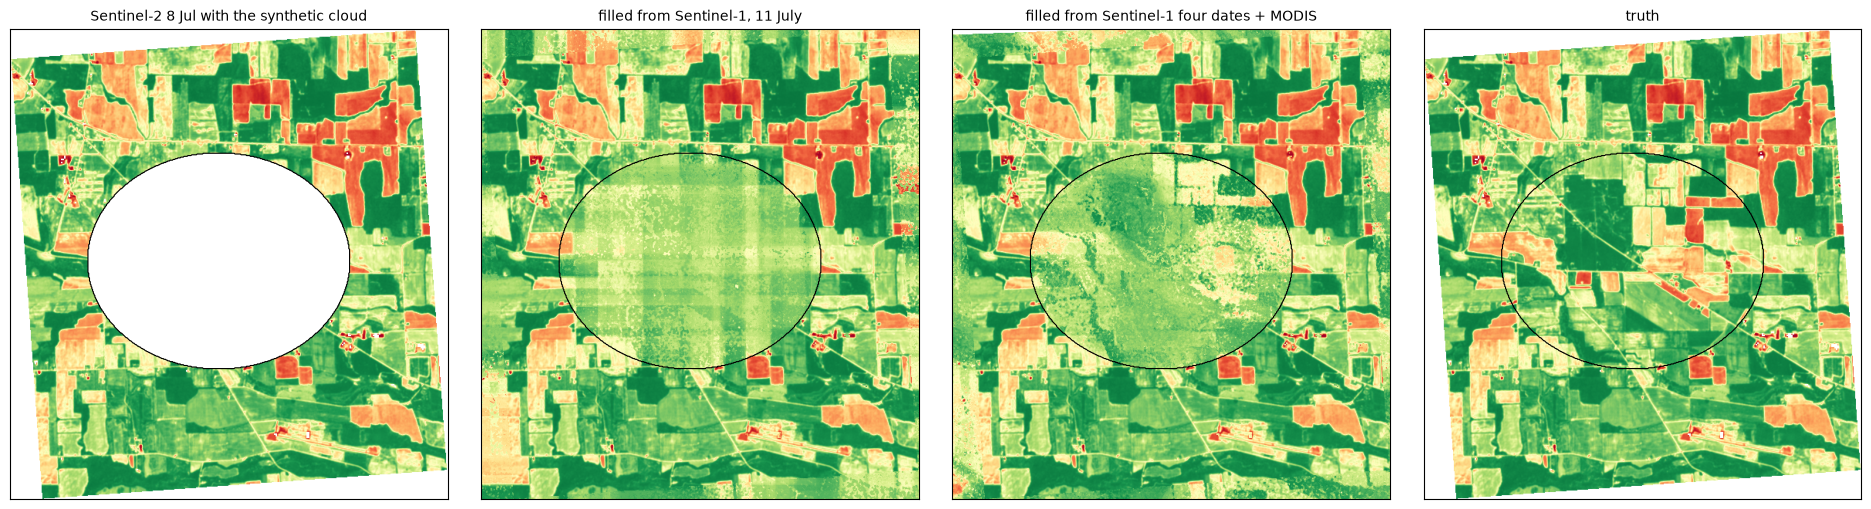

In [9]:
nd = lambda ds: (ds["nir"] - ds["red"]) / (ds["nir"] + ds["red"])  # NDVI of a Dataset
maps = {"Sentinel-2 8 Jul with the synthetic cloud": nd(cloudy), "filled from Sentinel-1, 11 July": nd(filled_all["Sentinel-1, 11 July"]),  # the four NDVI panels
        "filled from Sentinel-1 four dates + MODIS": nd(filled_all["Sentinel-1, four dates + MODIS"]), "truth": nd(opt)}
fig, ax = plt.subplots(1, 4, figsize=(19, 5))  # four panels
for a, (t, v) in zip(ax, maps.items()):  # each panel
    a.imshow(v, cmap="RdYlGn", vmin=0.1, vmax=0.95); a.contour(cloud.astype(int), levels=[0.5], colors="k", linewidths=0.8)  # NDVI and cloud edge
    a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([])  # title, no ticks
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the gap-filling results.** Under the cloud, Sentinel-1 of one date is barely better than filling with the scene mean, and in the NIR it is worse (negative R²). Four dates help, and adding the coarse MODIS composite helps most for red and NIR. Yet the hold-out R² that `sar_assisted_gap_fill` reports on clear pixels is 0.66 to 0.88. Those hold-out pixels lie scattered among the training pixels, and the pixel coordinates are among the predictors, so the model can interpolate from close neighbours, which it cannot do in the middle of a large cloud. The rectangular stripes inside the filled area are the same effect: the random forest splits on the coordinates. Validate gap filling under a realistic cloud, never on a random hold-out alone.


## Scale effects: from NAIP to Sentinel-2, Landsat and MODIS pixels

### Vegetation cover at 0.6 m as the reference

A coarse pixel often contains several land covers. The 0.6 m NAIP image of 14 July resolves single trees, roads and farmsteads, so it can tell how much of each Sentinel-2, Landsat or MODIS pixel is vegetated. NAIP is read at 1.2 m (2 × 2 average) to save memory, NDVI is computed from its red and NIR bands, and pixels above an automatic (Otsu) threshold are vegetation. `upscale` then averages the binary map onto each sensor's grid: the result is the **true vegetation fraction** of every coarse pixel. Only coarse pixels at least 95 % covered by NAIP are kept.

Each sensor's own NDVI is turned into vegetation cover in two ways:

- **classified**: the pixel is vegetation or not (Otsu threshold on that sensor's NDVI), the usual output of a land-cover map;
- **fractional**: the fractional vegetation cover $(\mathrm{NDVI} - \mathrm{NDVI}_{soil}) / (\mathrm{NDVI}_{veg} - \mathrm{NDVI}_{soil})$, clipped to 0 to 1, with the 2nd and 98th NDVI percentiles of the AOI as the soil and vegetation end-members.

`compare` gives R², RMSE and bias of each against the NAIP fraction.


In [10]:
naip_path = IF / "HR" / "HR_Rural_AOI_July_14.tif"  # NAIP, 0.6 m, red/green/blue/NIR
with rasterio.open(naip_path) as src:  # read at 1.2 m (2 x 2 average)
    # NAIP at half resolution (block average)
    arr = src.read(out_shape=(src.count, src.height // 2, src.width // 2), resampling=Resampling.average).astype("float32")
    tr = src.transform * src.transform.scale(src.width / arr.shape[2], src.height / arr.shape[1])  # 1.2 m transform
    naip_crs = src.crs  # its CRS
arr[:, (arr == 0).all(axis=0) | (arr >= 256).any(axis=0)] = np.nan  # no data outside the AOI
xs_n = tr.c + (np.arange(arr.shape[2]) + 0.5) * tr.a  # pixel-centre eastings
ys_n = tr.f + (np.arange(arr.shape[1]) + 0.5) * tr.e  # pixel-centre northings
naip_ndvi = (arr[3] - arr[0]) / (arr[3] + arr[0])  # NAIP NDVI (digital numbers, relative only)
veg_thr = threshold_otsu(naip_ndvi[np.isfinite(naip_ndvi)])  # automatic vegetation threshold
# NAIP vegetation mask (missing where NAIP has no data)
veg = xr.DataArray(np.where(np.isfinite(naip_ndvi), (naip_ndvi > veg_thr).astype("float32"), np.nan),
                   dims=("y", "x"), coords={"y": ys_n, "x": xs_n}).rio.write_crs(naip_crs)  # 1 = vegetation
covered = veg.notnull().astype("float32")  # 1 where NAIP has data
print(f"NAIP at 1.2 m: {veg.shape}, NDVI threshold {veg_thr:.3f}, vegetation cover {float(veg.mean()):.1%}")  # size, threshold and cover

SENSORS = {"Sentinel-2 (10 m)": (s2.sel(band="red"), s2.sel(band="nir")),  # sensor -> red, NIR
           "Landsat 8 (30 m)": (landsat.sel(band="red"), landsat.sel(band="nir")),
           "MODIS (463 m)": (mod[193].sel(band="red"), mod[193].sel(band="nir"))}  # sensor -> red, NIR
scale_rows, scale_maps = {}, {}  # scores and maps
for name, (red, nir) in SENSORS.items():  # every sensor
    v = ndvi(red, nir)  # its NDVI
    frac = rs.fusion.upscale(veg, v, method="mean")  # true vegetation fraction of each pixel
    full = rs.fusion.upscale(covered, v, method="mean") >= 0.95  # pixels well covered by NAIP
    frac = frac.where(full & v.notnull())  # keep those only
    vv = v.values[np.isfinite(frac.values)]  # NDVI of the kept pixels
    cls = (v > threshold_otsu(vv)).astype("float32").where(frac.notnull())  # classified: 0 or 1
    lo, hi = np.percentile(vv, [2, 98])  # soil and vegetation end-members
    fvc = ((v - lo) / (hi - lo)).clip(0, 1).where(frac.notnull())  # fractional vegetation cover
    scale_maps[name] = (frac, cls, fvc)  # for the figure
    for method, p in (("classified (0 or 1)", cls), ("fractional cover from NDVI", fvc)):  # both methods
        c = rs.fusion.compare(p, frac)  # agreement with the NAIP fraction
        scale_rows[name, method] = {"pixels": c["n"], "true cover": float(frac.mean()), "estimated cover": float(p.mean()),  # agreement with the NAIP fraction
                                    "R2": c["r2"], "RMSE": c["rmse"], "bias": c["bias"]}
pd.DataFrame(scale_rows).T.round(3)  # show it

NAIP at 1.2 m: (5380, 5053), NDVI threshold 0.282, vegetation cover 58.7%


pixels  true cover  \
Sentinel-2 (10 m) classified (0 or 1)         298784.0       0.587   
                  fractional cover from NDVI  298784.0       0.587   
Landsat 8 (30 m)  classified (0 or 1)          32865.0       0.588   
                  fractional cover from NDVI   32865.0       0.588   
MODIS (463 m)     classified (0 or 1)            103.0       0.572   
                  fractional cover from NDVI     103.0       0.572   

                                              estimated cover     R2   RMSE  \
Sentinel-2 (10 m) classified (0 or 1)                   0.661  0.057  0.429   
                  fractional cover from NDVI            0.652  0.351  0.356   
Landsat 8 (30 m)  classified (0 or 1)                   0.660 -0.019  0.414   
                  fractional cover from NDVI            0.646  0.415  0.314   
MODIS (463 m)     classified (0 or 1)                   0.592 -2.923  0.400   
                  fractional cover from NDVI            0.651  0.270  0.173   

                                               bias  
Sentinel-2 (10 m) classified (0 or 1)         0.074  
                  fractional cover from NDVI  0.065  
Landsat 8 (30 m)  classified (0 or 1)         0.072  
                  fractional cover from NDVI  0.059  
MODIS (463 m)     classified (0 or 1)         0.020  
                  fractional cover from NDVI  0.078

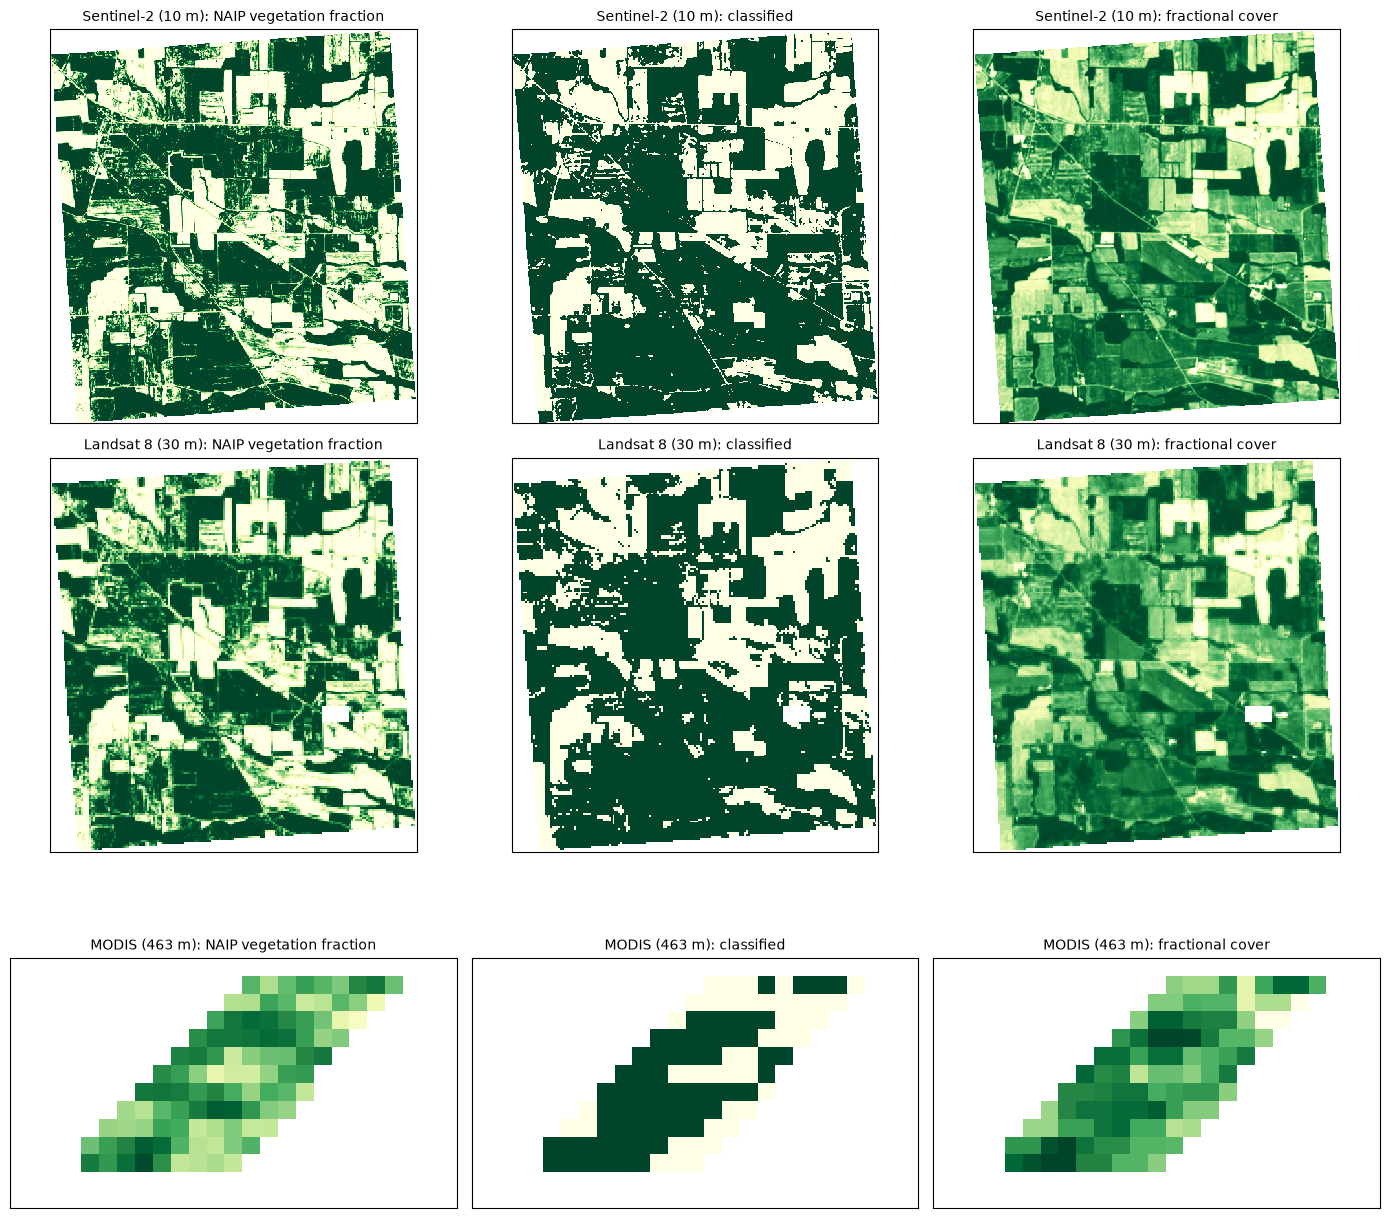

In [11]:
fig, ax = plt.subplots(3, 3, figsize=(14, 13))  # sensors x (truth, classified, fractional)
for r, (name, (frac, cls, fvc)) in enumerate(scale_maps.items()):  # each sensor
    # the three panels
    for c, (t, v) in enumerate((("NAIP vegetation fraction", frac), ("classified", cls), ("fractional cover", fvc))):
        ax[r, c].imshow(v, cmap="YlGn", vmin=0, vmax=1, interpolation="nearest")  # the map
        ax[r, c].set_title(f"{name}: {t}", fontsize=10); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])  # title
plt.tight_layout(); plt.show()  # arrange and draw

**Reading the scale results.** Classifying each pixel as vegetated or not throws the mixture away: at every resolution its R² against the NAIP fraction is near zero or negative, and at 463 m it is far below zero, even though its scene-wide cover happens to be close. The fractional cover from NDVI follows the NAIP fraction much better (R² 0.27 to 0.42), and its per-pixel error shrinks as the pixels grow (RMSE 0.36 at 10 m, 0.17 at 463 m) because mixtures average out. Most estimates put the cover 6 to 8 points higher than NAIP: NAIP was flown on 14 July, its NDVI comes from uncalibrated digital numbers, and the Otsu threshold is one choice among many, so the reference itself is uncertain by a few points.


## Multi-sensor classification

### Features from three sensor families

The last question is the one this chapter is about: does fusing sensors give a better land-cover map? The 2019 CDL is the reference, on the 30 m Landsat grid, recoded to the eight classes that cover this AOI. Three feature sets describe each 30 m pixel:

- **optical, one date**: the six Landsat reflectances of 9 July and NDVI;
- **radar time series**: Sentinel-1 VV and VH of the four dates (averaged onto 30 m in linear units, then converted to dB);
- **MODIS time series**: NDVI and NIR of the seven 8-day composites, with the cloudy pixels of 20 to 27 July interpolated in time from the neighbouring composites (and the shadowed pixels of the last composite taken from the one before), resampled bilinearly to 30 m.

**Early fusion** stacks all features into one input (`fuse_early` stacks the optical and radar arrays, and the MODIS bands are appended); **late fusion** trains one model per sensor family and averages their class probabilities (`fuse_late`). The split is by 600 m spatial blocks (`spatial_block_split`), so test pixels are not neighbours of training pixels.


In [12]:
CLASSES = ["Corn", "Alfalfa/hay", "Soybeans", "Winter wheat", "Forest", "Developed", "Grass/fallow", "Other"]  # 8 classes
# CDL codes of each class
CODES = {0: [1, 12, 13], 1: [36, 37], 2: [5], 3: [24], 4: [141, 142, 143, 190], 5: [121, 122, 123, 124], 6: [176, 61]}
y_map = np.full(cdl30.shape, 7, "int16")  # every other code is "Other"
for k, codes in CODES.items():  # recode the mapped codes
    y_map[np.isin(cdl30, codes)] = k  # paint the class
y_map[cdl30 == 0] = -1  # no data
conf30 = on_ls(cdl_conf, Resampling.nearest).values  # CDL confidence on the Landsat grid

opt_da = xr.concat([landsat.sel(band=["blue", "green", "red", "nir", "swir1", "swir2"]),  # Landsat bands and NDVI
                    ndvi(landsat.sel(band="red"), landsat.sel(band="nir")).expand_dims(band=["ndvi"])], dim="band")
# Sentinel-1 dB averaged onto the Landsat grid
sar_da = xr.concat([10 * np.log10(on_ls(10 ** (da / 10), Resampling.average)).assign_coords(band=[f"{p}_{d:%m%d}" for p in ("vv", "vh")])
                    for d, da in s1.items()], dim="band")  # radar time series on 30 m (averaged in linear units)
mts = xr.concat([xr.concat([ndvi(mod[d].sel(band="red"), mod[d].sel(band="nir")).drop_vars("band", errors="ignore"),  # (composite, variable, y, x)
                             mod[d].sel(band="nir").drop_vars("band", errors="ignore")], dim="var") for d in MODIS_DOY],
                dim="doy").assign_coords(doy=MODIS_DOY, var=["ndvi", "nir"])  # (composite, variable, y, x) on the MODIS grid
mts = mts.interpolate_na("doy")  # fill cloudy composites linearly from their neighbours in time
mts = mts.interpolate_na("doy", method="nearest", fill_value="extrapolate")  # first or last composite: nearest date
print("MODIS values still missing after interpolation:", int(mts.isnull().sum()))  # only an inner composite was cloudy
mod_da = mts.stack(band=("var", "doy")).transpose("band", "y", "x")  # one band per variable and composite
# band names of the MODIS features
mod_da = mod_da.assign_coords(band=[f"{v}_{d}" for v, d in mod_da.band.values]).drop_vars(["var", "doy"], errors="ignore")
mod_da = on_ls(mod_da.rio.write_crs(mod[MODIS_DOY[0]].rio.crs), Resampling.bilinear)  # bilinear onto 30 m
early = ic.fuse_early(opt_da.rio.write_crs(landsat.rio.crs), sar_da.rio.write_crs(landsat.rio.crs))  # optical + radar
early = xr.concat([early, mod_da.assign_coords(band=[f"modis_{b}" for b in mod_da.band.values])], dim="band")  # + MODIS
# the feature sets compared
FEATURES = {"optical, 1 date (Landsat)": opt_da, "radar, 4 dates (Sentinel-1)": sar_da,
            "MODIS, 7 composites": mod_da, "early fusion (all)": early}  # feature sets
X = {k: v.values.reshape(v.sizes["band"], -1).T for k, v in FEATURES.items()}  # (pixel, feature)
ok = (y_map.ravel() >= 0) & np.all([np.isfinite(v).all(axis=1) for v in X.values()], axis=0)  # complete pixels
gx, gy = np.meshgrid(LS_GRID.x.values, LS_GRID.y.values)  # pixel coordinates
idx = np.flatnonzero(ok)  # usable pixels
# spatial block split (600 m blocks)
split = ic.spatial_block_split(np.c_[gx.ravel()[idx], gy.ravel()[idx]], block_size=600, test_size=0.3,
                               seed=SEED, stratify=y_map.ravel()[idx])  # 600 m blocks
tr, te = idx[split.train], idx[split.test]  # training and test pixels
y = y_map.ravel()  # labels of every pixel
# feature counts and sample sizes
print({k: v.shape[1] for k, v in X.items()}, "features |", len(tr), "training and", len(te), "test pixels")
pd.Series(y[ok]).map(dict(enumerate(CLASSES))).value_counts().to_frame("pixels").T  # class sizes

MODIS values still missing after interpolation: 0
{'optical, 1 date (Landsat)': 7, 'radar, 4 dates (Sentinel-1)': 8, 'MODIS, 7 composites': 14, 'early fusion (all)': 29} features | 23900 training and 9289 test pixels


,Corn,Alfalfa/hay,Forest,Grass/fallow,Developed,Soybeans,Other,Winter wheat
pixels,10938,8650,5839,2185,1661,1537,1293,1086


In [13]:
def rf():  # the classifier used for every feature set
    # the random forest
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)


names = dict(enumerate(CLASSES))  # class id -> name
models, proba, cls_rows, per_class = {}, {}, {}, {}  # models, test probabilities and scores
hi_conf = conf30.ravel()[te] >= 80  # test pixels where the CDL itself is confident
for name, Xf in X.items():  # every feature set
    m = rf().fit(Xf[tr], y[tr])  # train
    models[name], proba[name] = m, m.predict_proba(Xf[te])  # keep the model and its probabilities
    yhat = m.classes_[proba[name].argmax(1)]  # predicted classes
    rep = ic.classification_report(y[te], yhat, labels=list(range(len(CLASSES))), class_names=names)  # scores
    cls_rows[name] = {"features": Xf.shape[1], "overall accuracy": rep["overall_accuracy"], "kappa": rep["kappa"],  # overall scores
                      "macro F1": rep["macro_f1"], "accuracy where CDL confidence >= 80": np.mean(yhat[hi_conf] == y[te][hi_conf])}
    per_class[name] = rep["per_class"]["f1"]  # F1 per class
late = ic.fuse_late([proba[k] for k in list(X)[:3]])  # average of the three single-sensor models
pred_late = models[list(X)[0]].classes_[late.argmax(1)]  # late-fusion classes
rep = ic.classification_report(y[te], pred_late, labels=list(range(len(CLASSES))), class_names=names)  # scores
cls_rows["late fusion (mean probability)"] = {"features": np.nan, "overall accuracy": rep["overall_accuracy"], "kappa": rep["kappa"],  # overall scores
                                              "macro F1": rep["macro_f1"], "accuracy where CDL confidence >= 80": np.mean(pred_late[hi_conf] == y[te][hi_conf])}
per_class["late fusion (mean probability)"] = rep["per_class"]["f1"]  # F1 per class
display(pd.DataFrame(cls_rows).T.round(3))  # overall scores
pd.DataFrame(per_class).round(3)  # F1 per class and feature set

,features,overall accuracy,kappa,macro F1,accuracy where CDL confidence >= 80
"optical, 1 date (Landsat)",7.0,0.676,0.575,0.564,0.781
"radar, 4 dates (Sentinel-1)",8.0,0.573,0.430,0.344,0.649
"MODIS, 7 composites",14.0,0.479,0.310,0.387,0.549
early fusion (all),29.0,0.710,0.620,0.598,0.808
late fusion (mean probability),NaN,0.695,0.593,0.532,0.801


,"optical, 1 date (Landsat)","radar, 4 dates (Sentinel-1)","MODIS, 7 composites",early fusion (all),late fusion (mean probability)
Corn,0.742,0.709,0.586,0.774,0.771
Alfalfa/hay,0.662,0.515,0.464,0.723,0.698
Soybeans,0.528,0.089,0.207,0.275,0.262
Winter wheat,0.855,0.255,0.410,0.836,0.801
Forest,0.813,0.713,0.477,0.828,0.821
Developed,0.343,0.004,0.137,0.291,0.193
Grass/fallow,0.126,0.043,0.157,0.298,0.082
Other,0.443,0.424,0.657,0.761,0.628


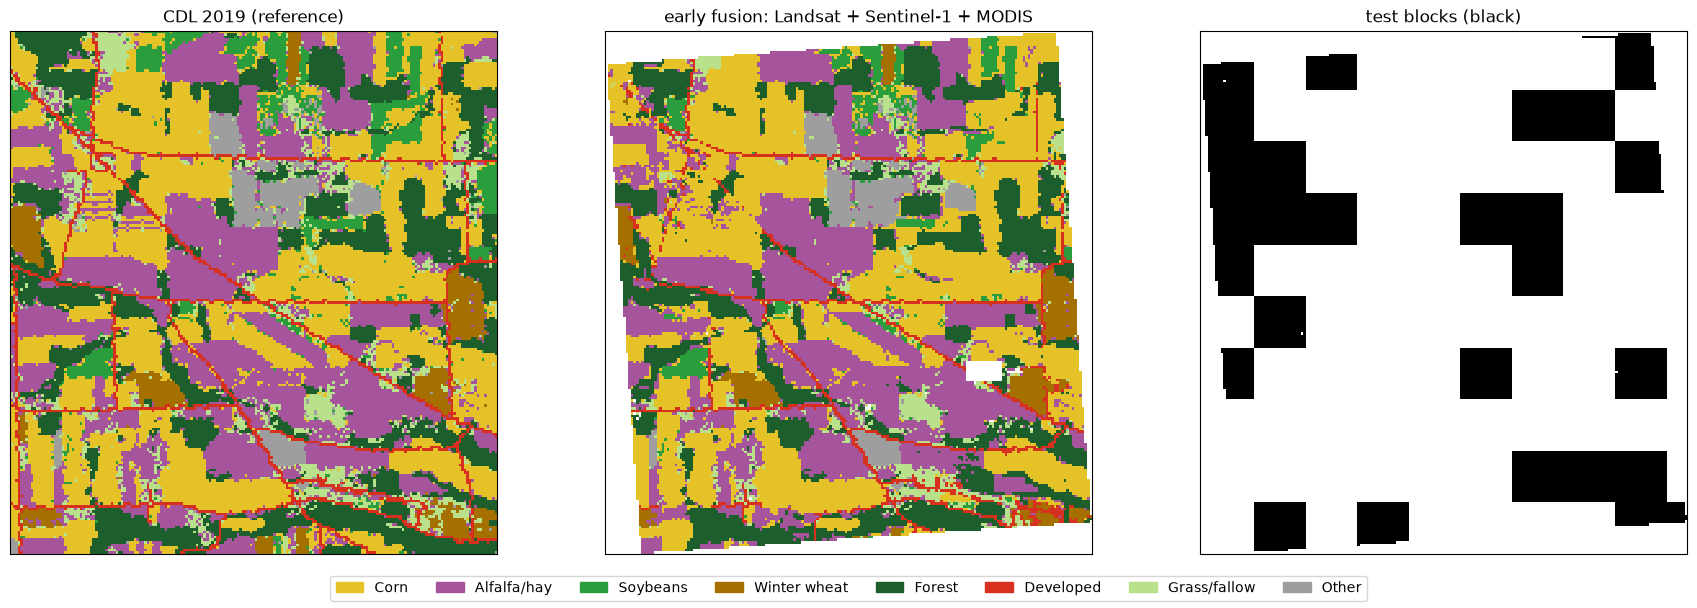

In [14]:
cmap8 = ListedColormap(["#e6c229", "#a6559d", "#2a9d3c", "#a57000", "#1c5f2c", "#d7301f", "#b9e08b", "#9e9e9e"])  # class colours
full_pred = np.full(y.shape, np.nan)  # map of the early-fusion model
full_pred[ok] = models["early fusion (all)"].predict(X["early fusion (all)"][ok])  # predict every complete pixel
test_mask = np.zeros(y.shape, bool); test_mask[te] = True  # test pixels
fig, ax = plt.subplots(1, 3, figsize=(18, 6))  # three panels
ax[0].imshow(np.where(y_map >= 0, y_map, np.nan), cmap=cmap8, vmin=-0.5, vmax=7.5, interpolation="nearest")  # reference
ax[0].set_title("CDL 2019 (reference)")  # title
ax[1].imshow(full_pred.reshape(y_map.shape), cmap=cmap8, vmin=-0.5, vmax=7.5, interpolation="nearest")  # prediction
ax[1].set_title("early fusion: Landsat + Sentinel-1 + MODIS")  # title
# test blocks
ax[2].imshow(test_mask.reshape(y_map.shape), cmap="Greys", interpolation="nearest"); ax[2].set_title("test blocks (black)")
for a in ax:  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
# class legend
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap8(i)) for i in range(8)], labels=CLASSES, loc="lower center", ncol=8)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()  # arrange and draw

**Reading the classification results.** One summer Landsat image is the strongest single source (68 % overall accuracy); the radar time series alone reaches 57 %, and the MODIS time series 48 %, too coarse for fields of a few hectares. Early fusion gives the best map overall (71 %, macro F1 0.60), with the clearest gains for classes that differ in timing or structure rather than colour: forest, alfalfa/hay, grass/fallow and "other". Late fusion, which averages three models of very unequal quality, gains less. Soybeans are the exception: the single Landsat date separates them best, and every combination dilutes that signal. On the pixels where the CDL itself is confident (80 % or more), every accuracy rises by about ten points, a reminder that part of the remaining error lies in the reference.


## Export the fused products

The STARFM predictions of 14 and 24 July (red and NIR at 30 m) and the early-fusion land-cover map are written as Cloud-Optimized GeoTIFFs with `rs.write`. Their metadata record the inputs and the scores measured above, so the files carry their own validation.


In [15]:
for date in TARGETS:  # each STARFM date
    da = xr.concat([pred[date, "red"], pred[date, "nir"]], dim="band").assign_coords(band=["red", "nir"])  # red, NIR
    da = da.rio.write_crs(landsat.rio.crs).rio.write_nodata(np.nan)  # georeference
    da.attrs = {"method": "STARFM (geolattice.rsense.fusion.starfm, window 31)", "fine_t1": "Landsat 8, 2019-07-09",  # provenance and score
                "coarse": f"MOD09A1 A2019{T1_DOY} and A2019{TARGETS[date][0]}", "validated_against": TARGETS[date][1],
                "rmse_nir": f"{starfm_tab.loc[(date, 'nir'), ('RMSE all', 'STARFM')]:.4f}"}  # provenance and score
    rs.write(da, OUTPUT_DIR / f"starfm_landsat_like_{date.replace('-', '')}.tif")  # Cloud-Optimized GeoTIFF
lc = LS_GRID.copy(data=np.nan_to_num(full_pred.reshape(y_map.shape), nan=255).astype("uint8")).rio.write_nodata(255)  # class map
lc.attrs = {"classes": "; ".join(f"{i}={c}" for i, c in enumerate(CLASSES)), "features": "Landsat 9 Jul + Sentinel-1 x4 + MODIS x7",  # classes, inputs and score
            "reference": "USDA CDL 2019", "test_overall_accuracy": f"{cls_rows['early fusion (all)']['overall accuracy']:.3f}"}
rs.write(lc.rename("land_cover"), OUTPUT_DIR / "early_fusion_landcover_2019.tif")  # Cloud-Optimized GeoTIFF
print(sorted(p.name for p in OUTPUT_DIR.glob("*.tif")))  # files written

['early_fusion_landcover_2019.tif', 'starfm_landsat_like_20190714.tif', 'starfm_landsat_like_20190724.tif']


## Interpretation and limitations

- **STARFM needs coarse change that fine pixels share, and a correct coarse change.** It improves on "no change" where whole fields changed between the dates in a way MODIS could see; where change is smaller than a 463 m MODIS pixel, or differs between neighbouring fields inside one MODIS pixel, it can only spread the average change (ESTARFM and FSDAF add spectral unmixing for that case). On 24 July the MODIS NIR change was itself too large, and STARFM passed the error on.
- **Cross-sensor references carry their own error.** PlanetScope and RapidEye were put on Landsat's scale with a per-band linear fit on stable forest and developed pixels. Their different spectral bands, viewing geometry and residual misregistration remain in the reference, so part of every RMSE belongs to the reference, not to the fusion.
- **SAR fills patterns, not pigments.** Backscatter responds to structure, roughness and moisture rather than leaf colour, so a single radar date explained little of the optical reflectance under the cloud; several dates and a coarse cloud-free optical source (MODIS) explained more. A random hold-out of clear pixels overstated the quality of every fill. Every filled pixel stays flagged as `reconstructed`.
- **Pixels mix.** A classified coarse pixel is all or nothing; its errors grow with pixel size and cancel only partly over the scene. Fractional estimates are closer to the truth, and a fine reference such as NAIP is the way to check them. NAIP digital numbers are not calibrated, so only NAIP's spatial pattern was used.
- **Fusion helped classification, modestly.** Early fusion added about three points of overall accuracy and four of macro F1 over the best single sensor, mostly for classes that differ in timing or structure (forest, hay, grass/fallow, other). Late fusion of three models of unequal quality gained less, and soybeans were mapped best by the optical date alone. Late fusion is simpler and copes with a missing sensor; early fusion lets one model use interactions between sensors.
- **The CDL is a reference, not the truth.** Its own accuracy varies by class (its confidence layer is given above); hay, fallow and grass are often confused in the CDL itself.
- **Data quirks.** The two local RapidEye files labelled 14 and 24 July are the same 24 July scene; the PlanetScope image of 14 July is in UTM zone 18N (NAD83) and was reprojected; MOD09A1 composites can mix observations from any day of their 8-day window.

### References

- Gao, F., Masek, J., Schwaller, M., Hall, F. (2006). On the blending of the Landsat and MODIS surface reflectance: predicting daily Landsat surface reflectance. IEEE TGRS 44(8).
- Zhu, X., Chen, J., Gao, F., Chen, X., Masek, J. G. (2010). An enhanced spatial and temporal adaptive reflectance fusion model (ESTARFM). Remote Sensing of Environment 114.
- Schott, J. R., Salvaggio, C., Volchok, W. J. (1988). Radiometric scene normalization using pseudoinvariant features. Remote Sensing of Environment 26.
- Gutman, G., Ignatov, A. (1998). The derivation of the green vegetation fraction from NOAA/AVHRR data. International Journal of Remote Sensing 19.
- Schmitt, M., Zhu, X. X. (2016). Data fusion and remote sensing: an ever-growing relationship. IEEE Geoscience and Remote Sensing Magazine 4(4).
- Vermote, E. (2015). MOD09A1 MODIS/Terra Surface Reflectance 8-Day L3 Global 500 m SIN Grid V006/061. NASA EOSDIS LP DAAC.
- USDA NASS Cropland Data Layer. https://www.nass.usda.gov/Research_and_Science/Cropland/
